# 02 · Finding near-duplicate problems

Codeforces often publishes two versions of one problem, an easy one and a hard one, with
nearly the same statement and usually the same tags. A split that puts one version in
training and the other in test **leaks data**: the model is tested on a problem it has
practically seen, so its test score is inflated. To prevent this, a split must keep
duplicates in the same group. This notebook shows how they are found.

**In short**
- **The leakage risk is real.** 69 of the 82 duplicate pairs have the same focus tags,
  and a random 80/20 split would separate about 26 pairs.
- **A similarity threshold alone cannot find them.** At 0.8 it misses 11 of the 82
  duplicate pairs. At 0.4 it misses none, but links unrelated problems into groups of up
  to 11.
- **So the detector has two stages.** A low similarity threshold misses nothing, then the
  verdicts of LLM judges remove what is not a duplicate. Together they keep all 82
  duplicates together and group no non-duplicate.
- **The verdicts were produced once.** Two blind LLM judges labelled each pair, and their
  verdicts are frozen in `assets/near_duplicates/judgments.csv`. Splitting reads them,
  with no model call.

The audit's code, prompts and commands are in `codeforces_tags.near_duplicates`; its
results and how to rerun it are in
[`assets/near_duplicates/`](../assets/near_duplicates/README.md).

How the detector works (source: `figures/near_duplicate_pipeline.mmd`):

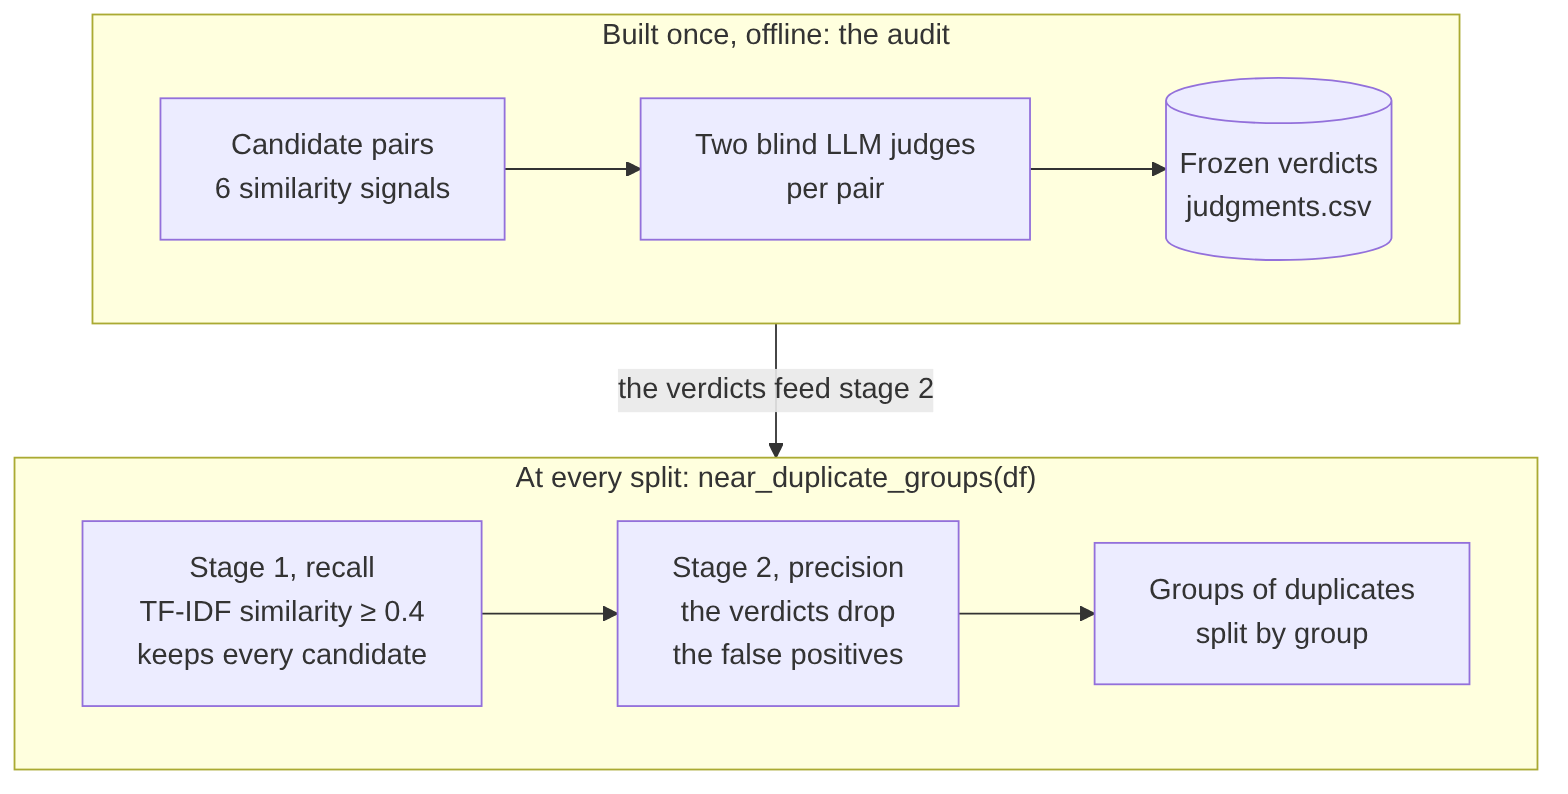

In [1]:
from IPython.display import Image

Image(filename="figures/near_duplicate_pipeline.png", width=760)

In [2]:
import json
import math

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from codeforces_tags.analysis.near_duplicate_quality import (
    describe_pair,
    detection_curve,
    two_stage_errors,
    zero_failure_upper_bound,
)
from codeforces_tags.analysis.plotting import setup_style
from codeforces_tags.config import (
    AUDIT_FORMER_THRESHOLD,
    FOCUS_TAGS,
    NEAR_DUPLICATE_AUDIT_DIR,
    NEAR_DUPLICATE_CANDIDATE_THRESHOLD,
    NEAR_DUPLICATE_FIELD,
)
from codeforces_tags.data.labels import multi_hot
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.near_duplicates.audit.prompts import render_prompt
from codeforces_tags.near_duplicates.audit.verdicts import DUPLICATE_LABELS
from codeforces_tags.near_duplicates.detection import (
    groups_from_pairs,
    near_duplicate_groups,
    similar_pairs,
)

setup_style()
pd.set_option("display.max_colwidth", 110)

df = load_dataset()
statements = df[NEAR_DUPLICATE_FIELD]
judgments = pd.read_csv(NEAR_DUPLICATE_AUDIT_DIR / "judgments.csv")
metadata = json.loads((NEAR_DUPLICATE_AUDIT_DIR / "audit_metadata.json").read_text())
is_duplicate = judgments["final"] == "duplicate"
confirmed = judgments[is_duplicate]
print(f"{len(df):,} problems, {len(judgments)} judged pairs, {is_duplicate.sum()} duplicates")

4,982 problems, 485 judged pairs, 82 duplicates


## 1. The risk: data leakage across the split

A duplicate pair is two near-identical statements, and most of the time the same tags.
The table below takes the 82 pairs confirmed in the audit. It shows how many share their
focus tags, and how many a random split would separate:

In [3]:
focus_tags = multi_hot(df["tags"], FOCUS_TAGS)
same_focus = (
    focus_tags.loc[confirmed["sample_id_a"]].to_numpy()
    == focus_tags.loc[confirmed["sample_id_b"]].to_numpy()
).all(axis=1)
test_share = 0.2
separated = 2 * test_share * (1 - test_share)  # one in train, the other in test, or the reverse
split = f"{1 - test_share:.0%}/{test_share:.0%}"
pd.Series(
    {
        "duplicate pairs": len(confirmed),
        "with the same focus tags": same_focus.sum(),
        f"chance a random {split} split separates a pair": f"{separated:.0%}",
        "pairs separated, on average": round(separated * len(confirmed)),
    },
    name="value",
).to_frame()

,value
duplicate pairs,82
with the same focus tags,69
chance a random 80%/20% split separates a pair,32%
"pairs separated, on average",26


**What leaks.** About 26 test problems would have a near copy in training, nearly always
with the same answer. The model can score on them by recognising the statement, without
learning anything that carries over to new problems. The leak does three things:
- **It inflates the test score**, most for the tags where versions are common.
- **It biases every choice made on held-out data**: model, features, per-tag thresholds.
  The same leak exists between cross-validation folds.
- **It is invisible in the metrics.** Nothing in the score shows that part of the test
  set was seen in another form.

The fix is to split by group: every problem in a group of duplicates goes to the same
side. The rest of the notebook is about finding those groups without missing pairs.

## 2. Why one similarity threshold is not enough

Each statement becomes a TF-IDF vector (word 1–2 grams of the description), and two
problems are compared by the cosine of their vectors. The question is where to cut. Every
pair at or above 0.4 was judged (section 4), so this curve is exact from 0.4 up. Its
recall counts the 82 duplicates found.

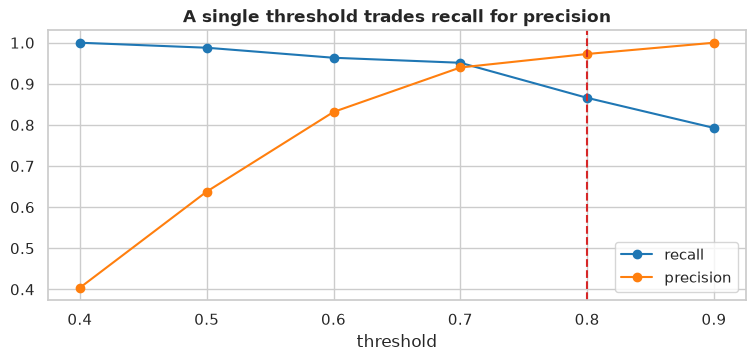

,duplicates kept together,duplicates missed,non-duplicates grouped,recall,precision
threshold,,,,,
0.4,82,0,121,1.000,0.404
0.5,81,1,46,0.988,0.638
0.6,79,3,16,0.963,0.832
0.7,78,4,5,0.951,0.940
0.8,71,11,2,0.866,0.973
0.9,65,17,0,0.793,1.000


In [4]:
curve = detection_curve(judgments["word_cosine"], is_duplicate, [0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
ax = curve[["recall", "precision"]].plot(marker="o", figsize=(9, 3.5))
ax.axvline(AUDIT_FORMER_THRESHOLD, color="tab:red", linestyle="--")
ax.set(title="A single threshold trades recall for precision", xlabel="threshold", ylabel="")
plt.show()
curve.round(3)

**A high threshold misses duplicates.** At 0.8, 11 of the 82 duplicate pairs are missed.
They are versions whose wording changes more than their task. Here are the three least
similar:

In [5]:
missed = judgments[is_duplicate & (judgments["word_cosine"] < AUDIT_FORMER_THRESHOLD)]
for _, pair in missed.nsmallest(3, "word_cosine").iterrows():
    print(describe_pair(pair, statements), end="\n\n")

4494 / 4496: word cosine 0.497, verdict duplicate
  judge 1 (versions, medium confidence): Explicit B1/B2 Wonderful Coloring pair: same story and
    rules, generalised from 2 colours on a string to k colours on a sequence.
  judge 2 (versions, high confidence): These are Wonderful Coloring B1/B2; B2 generalises from two
    colours on a string to k colours on a sequence.
  [4494] This is a simplified version of the problem B2. Perhaps you should read the problem B2
    before you start solving B1. Paul and Mary have a favorite string s which consists of lowercase
    letters of the Latin alphabet. They want to paint it using pieces of chalk of two colors: red
    and green. Let's call a coloring of a string wonderful if the following conditions are met: each
    letter of the string is ei…
  [4496] This problem is an extension of the problem "Wonderful Coloring - 1". It has quite many
    differences, so you should read this statement completely. Recently, Paul and Mary have found a
 

**A low threshold links problems that are not duplicates.** At 0.4 nothing is missed,
but 121 of the 203 pairs it links are not duplicates. They share a story or a setting
and ask a different question. Here are the three most similar:

In [6]:
candidates = judgments[judgments["word_cosine"] >= NEAR_DUPLICATE_CANDIDATE_THRESHOLD]
rejected = candidates[candidates["final"] == "not_duplicate"]
for _, pair in rejected.nlargest(3, "word_cosine").iterrows():
    print(describe_pair(pair, statements), end="\n\n")

4967 / 4969: word cosine 0.830, verdict not_duplicate
  judge 1 (related, medium confidence): Same William homework story, but avoiding abc as a substring
    vs as a subsequence needs a different algorithm.
  judge 2 (related, medium confidence): The statements are almost identical except substring versus
    subsequence 'abc', which makes these genuinely different tasks (counting versus segment-tree
    DP).
  [4967] Before becoming a successful trader William got a university degree. During his education
    an interesting situation happened, after which William started to listen to homework assignments
    much more attentively. What follows is the correct formal description of the homework
    assignment:You are given a string s of length n only consisting of characters "a", "b" and "c".
    There are q queries of format (…
  [4969] Before becoming a successful trader William got a university degree. During his education
    an interesting situation happened, after which William s

Word overlap cannot separate the two cases. A hard version (B2 for k colours on a
sequence) can share fewer words with its easy version than two different tasks written
around one story (substring vs subsequence). Telling them apart takes reading the task.

## 3. Why two stages

- **Stage 1 is for recall.** TF-IDF at 0.4 is cheap, and it keeps every duplicate found:
  the least similar scores 0.497. Its only flaw is false positives.
- **Stage 2 is for precision.** Each candidate gets a verdict from LLM judges who read
  both statements and decide whether the task is the same, which similarity cannot do.
- **The two errors do not cost the same.** A missed duplicate is a leak: a near copy of a
  test problem in training, which inflates the score. A wrong link only keeps two
  problems on the same side. So both stages err towards linking: a pair stays linked when the judges
  disagree, and when no judge has seen it.
- **The expensive stage runs once.** The dataset is fixed. So the 203 candidates were
  judged once, twice each, and the verdicts are frozen in a file. Splitting reads them in
  a fraction of a second, without calling a model.
- **Judging grows with the candidates, not with the pairs.** Only stage-1 candidates
  are sent to the judges: 203 of the 12.4 million pairs here. The audit also judged
  pairs below 0.4 (section 5), but only once, to check that the threshold misses
  nothing. On new data, `build-pairs` judges the candidates alone.

How `near_duplicate_groups(df)` decides for a pair of problems (source:
`figures/near_duplicate_decision.mmd`):

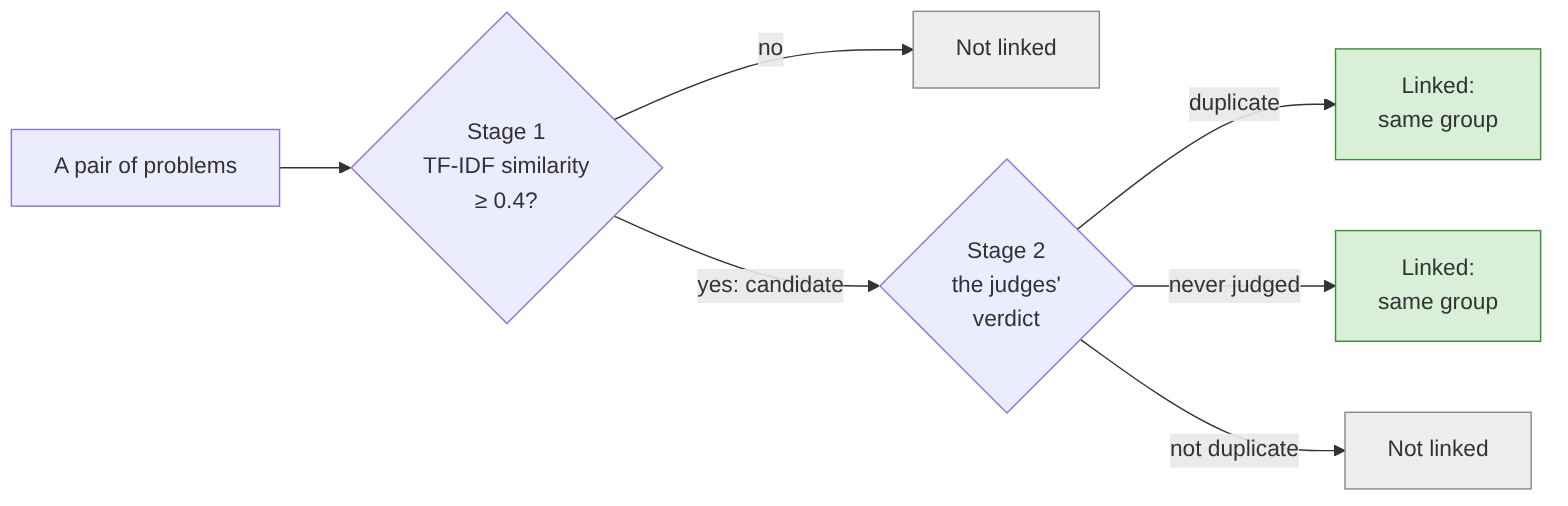

In [7]:
Image(filename="figures/near_duplicate_decision.png", width=760)

**The result.** The two stages get the recall of the low threshold and the precision of
the judges. On the full dataset:

In [8]:
grouping_options = {
    f"TF-IDF >= {t} alone": groups_from_pairs(df.index, similar_pairs(statements, t))
    for t in (AUDIT_FORMER_THRESHOLD, 0.5, NEAR_DUPLICATE_CANDIDATE_THRESHOLD)
}
grouping_options["two stages (default)"] = near_duplicate_groups(df)

non_duplicates = judgments[~is_duplicate]
options = {}
for name, groups in grouping_options.items():
    sizes = groups.value_counts()
    together = (
        groups[confirmed["sample_id_a"]].to_numpy() == groups[confirmed["sample_id_b"]].to_numpy()
    )
    grouped = (
        groups[non_duplicates["sample_id_a"]].to_numpy()
        == groups[non_duplicates["sample_id_b"]].to_numpy()
    )
    options[name] = {
        "duplicates kept together": f"{together.sum()} of {len(confirmed)}",
        "non-duplicates grouped": grouped.sum(),
        "largest group": sizes.max(),
    }
pd.DataFrame(options).T

,duplicates kept together,non-duplicates grouped,largest group
TF-IDF >= 0.8 alone,71 of 82,2,2
TF-IDF >= 0.5 alone,81 of 82,66,8
TF-IDF >= 0.4 alone,82 of 82,133,11
two stages (default),82 of 82,0,2


**What the second stage fixes.** The table counts the errors of the 0.8 threshold that
the two stages replace, and those of their own first stage:

In [9]:
two_stage_errors(
    judgments["word_cosine"],
    is_duplicate,
    is_duplicate,
    NEAR_DUPLICATE_CANDIDATE_THRESHOLD,
    AUDIT_FORMER_THRESHOLD,
)

,errors,fixed by the two-stage detector,left
false positives of one stage (>= 0.8),2,2,0
false negatives of one stage (>= 0.8),11,11,0
false positives of stage 1 (>= 0.4),121,121,0
false negatives of stage 1 (>= 0.4),0,0,0
stage 2 mistakes on stage-1 candidates,0,0,0


- **Stage 2 removes** all 121 false positives of stage 1.
- **Against the 0.8 threshold**, the detector recovers the 11 duplicates it missed and
  drops its 2 false links.
- **Stage 1 sets the recall ceiling.** At 0.5 it would already lose one duplicate
  (4494/4496, similarity 0.497), and no second stage can bring it back. Its threshold
  must stay low.

## 4. Where the verdicts come from

**Which pairs were judged.** A pair is a candidate when any of six signals flags it:
- word similarity, character similarity or similar code;
- an identical sample input;
- the same round, with some word overlap;
- two statements of one round that both announce a version.

The candidates and a random control fall into four tiers. Tiers A and B were judged in
full; C and D are random samples.

In [10]:
tiers = pd.DataFrame(metadata["tiers"]).T[["population", "judged"]]
tiers["duplicates found"] = [
    int((is_duplicate & (judgments["tier"] == tier)).sum()) for tier in tiers.index
]
tiers.rename(columns={"population": "pairs"})

,pairs,judged,duplicates found
A: word>=0.4,203,203,82
"B: word<0.4, strong signal",72,72,0
"C: word<0.4, weak signal only (sample)",247,60,0
"D: same contest, no signal (random control)",9651,150,0


**The judges.** Two blind LLM judges label each pair as the same problem, versions,
related or different. They see only the two statements: never the ids, the scores, nor
the other judge's label. A pair is a duplicate when at least one judge says "same
problem" or "versions". The prompts are Jinja2 templates in
`near_duplicates/audit/templates/`. Here are the settings of the recorded run, then the
first judge's prompt:

In [11]:
settings = [
    "model",
    "reasoning_effort",
    "extended_thinking",
    "temperature_and_token_limits",
    "output",
]
with pd.option_context("display.max_colwidth", None):
    display(
        pd.Series(
            {key: metadata["judges"][key] for key in settings}, name="recorded run"
        ).to_frame()
    )
print(render_prompt("first_pass", batch_file="<folder>/texts/batch_0.json"))

,recorded run
model,claude-opus-5-5
reasoning_effort,xhigh
extended_thinking,on: the recorded transcripts contain thinking blocks
temperature_and_token_limits,"harness defaults, not set"
output,"structured, validated against src/codeforces_tags/near_duplicates/audit/templates/labels.schema.json"


You judge whether two Codeforces problem statements describe the same underlying problem, to prevent train/test leakage in a tag-prediction dataset (knowing one problem's tags or solution would give away the other's).
Labels:
- same_problem: the same task (a copy, a re-wording, a translation, or a mirror of the same problem in another round).
- versions: easy/hard versions or subtasks of ONE problem: same story and task, differing only in constraints, limits or a small extra requirement.
- related: shares a story, characters or setting (e.g. the same round or series) but asks a genuinely different task.
- different: unrelated tasks.
Judge from the statement text only. Short or generic statements can share boilerplate; similar wording alone is not enough, the TASK must match for same_problem/versions. Use confidence=low when you cannot decide.

Read the JSON file <folder>/texts/batch_0.json (a list of items with pair_id, A and B; each side has description, input_spec, output_spec; long 

**Do the judges agree?** On the 203 candidates, on all but one pair:

In [12]:
first = candidates["judge1_label"].isin(DUPLICATE_LABELS).rename("judge 1 says duplicate")
second = candidates["judge2_label"].isin(DUPLICATE_LABELS).rename("judge 2 says duplicate")
display(pd.crosstab(first, second))
for _, pair in candidates[first != second].iterrows():
    print(describe_pair(pair, statements))

judge 2 says duplicate,False,True
judge 1 says duplicate,,
False,121,0
True,1,81


1028 / 3366: word cosine 0.950, verdict duplicate
  judge 1 (versions, medium confidence): Same Bob paper stripe story; cutting into two vs. three
    equal-sum pieces, a small extension of one task.
  judge 2 (related, medium confidence): Same Bob paper-stripe story, but cutting into two equal-sum
    pieces vs three is a genuinely different counting task.
  [1028] Once Bob took a paper stripe of n squares (the height of the stripe is 1 square). In each
    square he wrote an integer number, possibly negative. He became interested in how many ways
    exist to cut this stripe into two pieces so that the sum of numbers from one piece is equal to
    the sum of numbers from the other piece, and each piece contains positive integer amount of
    squares. Would you help Bob sol…
  [3366] Once Bob took a paper stripe of n squares (the height of the stripe is 1 square). In each
    square he wrote an integer number, possibly negative. He became interested in how many ways
    exist to cut t

The disputed pair tells the same story with a different count (two or three equal-sum
pieces). The default links it. Over all 485 judged pairs, the judges agree on 484.

## 5. How sure are we that nothing is missed?

No duplicate was found below 0.4: both judges found none in the 282 judged pairs below
it, including every pair with a strong signal. Tiers A and B were judged in full. For the
sampled tiers, finding 0 duplicates in n random pairs bounds the rate at 1 − 0.05^(1/n),
at 95%, which is about 3/n:

In [13]:
bounds = {}
for tier, info in metadata["tiers"].items():
    if info["judged"] < info["population"]:
        rate = zero_failure_upper_bound(info["judged"])
        at_most = math.ceil(rate * info["population"])
        bounds[tier] = {
            "judged": f"{info['judged']} of {info['population']:,}",
            "duplicates missed (95% bound)": f"< {rate:.1%}, at most {at_most}",
        }
display(pd.DataFrame(bounds).T)
all_pairs = len(df) * (len(df) - 1) // 2
same_round = metadata["tiers"]["D: same contest, no signal (random control)"]["population"]
unsampled = all_pairs - metadata["candidate_pairs"] - same_round
print(f"Pairs from different rounds that no signal flags (not sampled): {unsampled:,}")

,judged,duplicates missed (95% bound)
"C: word<0.4, weak signal only (sample)",60 of 247,"< 4.9%, at most 13"
"D: same contest, no signal (random control)","150 of 9,651","< 2.0%, at most 191"


Pairs from different rounds that no signal flags (not sampled): 12,397,498


**Limits.**
- **The bounds assume the two judges never both miss a duplicate.** Two LLM judges that
  agree may still share blind spots; a human check of a sample is the next step.
- **About 12.4 million pairs from different rounds were never sampled.** Only the
  signals cover them: each one is below every signal threshold. A random sample would
  not help: 150 pairs bound the rate at 2%, about 250,000 pairs.

## 6. Conclusion

- **Duplicates are a data-leakage risk.** 82 pairs of problems are near copies, 69 of them
  with the same focus tags, and a random split would separate about 26. Splitting by
  group removes the leak.
- **The default detector has two stages.** `near_duplicate_groups(df)` finds 82 pairs of
  duplicate problems, mostly easy and hard versions.
  - Stage 1, TF-IDF similarity ≥ 0.4, misses none of them.
  - Stage 2, the frozen verdicts of two LLM judges, removes the 121 false positives.
- **A single threshold would fail either way.** At 0.8 it misses 11 duplicates; at 0.4
  it links unrelated problems into groups of up to 11.
- **It costs one audit.** The 203 candidates were judged once, twice each, with the
  prompts and settings saved in the code. Splitting needs no model call.
- **The judges are consistent.** They agree on 202 of the 203 candidates, and on 484 of
  all 485 judged pairs.
- **No duplicate was found below 0.4.** The sampled tiers are bounded at 95%. The 12.4
  million cross-round pairs that no signal flags remain unsampled.